# O-RAN 7.2x 下行闭环仿真：逐模块演示

本 notebook 按信号流向把整个仿真拆成若干模块，每一步都直接调用 `oran/` 中的组件并画出中间结果，便于理解完整流程。
`scripts/rt_closed_loop.py`、`scripts/rt_compare_compression.py` 做的事情相同，只是把这些步骤封装起来批量运行、统计。

```
物理环境（射线追踪 / CDL）→ 信道
   │
O-DU：预编码（TDD 互易，由 CSI 计算 BD）
   │
测量时隙：CSI-RS + CSI-IM ─ 前传（Cat A/B、压缩）─ O-RU ─ 信道 ─ UE：估计 → CQI → UCI 上报
   │
MAC：CQI → MCS（+ OLLA）
   │
数据时隙：O-DU High-PHY（TB→LDPC→调制→层映射→RE 映射）─ 前传 ─ O-RU ─ 信道 ─ UE：DMRS 估计 → LMMSE → 译码 → CRC
   │
ACK/NACK → OLLA（下一个 CSI-RS 周期）
```

| 节 | 模块 | 代码 |
|---|---|---|
| 0–1 | 开关、初始化 | `oran/config.py` |
| 2 | 物理环境与信道 | `oran/rt_channel.py`、`oran/channel.py` |
| 3 | 资源网格：PDSCH、DMRS、CSI-RS / CSI-IM | `oran/pdsch.py`、`oran/csi_rs.py` |
| 4 | 预编码（O-DU） | `oran/precoding.py` |
| 5 | 测量时隙与 CQI（UE） | `oran/csi_rs.py`、`oran/csi.py`、`oran/bler_model.py` |
| 6 | 链路自适应（MAC） | `oran/link_adaptation.py` |
| 7 | 数据时隙：O-DU → 前传 → O-RU → 信道 → UE | `oran/odu.py`、`oran/fronthaul.py`、`oran/compression/`、`oran/oru.py`、`oran/ue.py`、`oran/channel_estimation.py` |
| 8 | 闭环（多个 CSI-RS 周期） | `oran/closed_loop.py` 的简化版 |
| 9 | 同一撒点上比较 Cat A/B × 压缩（可选） | `scripts/rt_compare_compression.py` 的简化版 |

**用法**：修改第 0 节的开关后，从头依次运行（"Run All"）。射线追踪需要 GPU 和 580 驱动的用户态库，
VS Code 的 Jupyter 内核通过项目根目录的 `.env` 自动设置 `LD_LIBRARY_PATH`。默认设置下整本运行约 2~3 分钟。

## 0. 开关

所有可切换的设定集中在这里。说明：

- `CHANNEL_MODEL = "rt"`：munich 场景中随机撒点，SNR 由位置和链路预算决定；`"cdl"`：一个固定的 CDL 信道实现（UE 静止），SNR 由 `SNR_DB` 给定。
- `CATEGORY`：Cat A 在 O-DU 预编码、前传天线端口流；Cat B 前传层流 + 预编码权值，由 O-RU 预编码。
- `UPLANE` / `BFW`：前传压缩方法与位宽。`("ideal", 16)` 为理想前传（不量化）。
- `CQI_SOURCE`：`"csi-rs"` 为真实测量（CSI-RS 经前传，能看到部分压缩失真）；`"genie"` 为真实等效信道（看不到前传）。

In [1]:
# ================================ 开关 ================================
# ---- 信道 ----
CHANNEL_MODEL = "rt"           # "rt"：Sionna RT 射线追踪（munich）；"cdl"：3GPP CDL
TX_POWER_DBM  = 35.0           # rt：O-RU 总发射功率 [dBm]（20 MHz）
DROP_SEED     = 1              # rt：撒点种子，换一个数就换一组 UE 位置
SNR_DB        = 25.0           # cdl：每接收天线的 SNR [dB]（rt 模式下忽略）
CDL_MODEL, DELAY_SPREAD = "C", 100e-9   # cdl：CDL 模型与时延扩展 [s]

# ---- 系统 ----
CATEGORY      = "A"            # "A"：预编码在 O-DU；"B"：预编码在 O-RU
NUM_UE        = 2              # 1：SU-MIMO；2：MU-MIMO（块对角化 BD）
LAYERS_PER_UE = 2              # 每 UE 层数：1、2、4
MCS_TABLE     = 2              # 1：最高 64QAM；2：最高 256QAM（CQI 表同号）

# ---- 前传压缩 ----
# 方法："ideal"（理想）、"none"（16 bit 定点）、"bfp"（块浮点）、"block_scaling"（块缩放）、"mu_law"（μ 律）
UPLANE = ("mu_law", 5)            # U-plane IQ
BFW    = ("mu_law", 5)            # Cat B 的 C-plane 波束赋形权值

# ---- UE 接收机与 CSI ----
CHANNEL_ESTIMATION = "ls"      # "ls"：DMRS LS 估计；"perfect"：理想信道
DELAY_COMPENSATION = True      # DMRS / CSI-RS 估计前补偿定时偏差
CQI_SOURCE    = "csi-rs"       # "csi-rs"：经前传的 CSI-RS / CSI-IM；"genie"：真实等效信道

# ---- 闭环 ----
OLLA             = True        # 外环链路自适应
NUM_PERIODS      = 12          # CSI-RS 周期数
SLOTS_PER_PERIOD = 7           # 每周期数据时隙数（另有 1 个测量时隙，周期共 8 个时隙）
WARMUP_PERIODS   = 3           # 统计时跳过的前若干周期（OLLA 收敛）

# ---- 可选：同一撒点上比较 Cat A/B × 压缩（约 1~2 分钟）----
RUN_COMPARISON = True
COMPARE_WIDTHS = [("ideal", 16), ("block_scaling", 5), ("mu_law", 5)]

DEVICE = "cuda:0"
SEED   = 42

## 1. 初始化

建立仿真配置 `ORANConfig` 和端到端链路 `ORANDownlink`（内含 O-DU、各 O-RU 的前传链路、O-RU、信道、UE 接收机）。

In [2]:
import os, sys, time, warnings
from dataclasses import replace

ROOT = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(ROOT, "oran")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
warnings.filterwarnings("ignore")
if "nvidia" not in os.environ.get("LD_LIBRARY_PATH", ""):
    print("提示：LD_LIBRARY_PATH 中没有 580 驱动的用户态库，射线追踪可能无法使用 GPU（见 .env / env.sh）")

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import sionna.phy
from sionna.phy import config as sionna_config

plt.rcParams["font.family"] = ["DejaVu Sans", "Droid Sans Fallback"]
plt.rcParams["axes.unicode_minus"] = False
torch.set_grad_enabled(False)

from oran import ORANConfig, ORANDownlink, CompressionConfig
from oran.channel import ChannelState
from oran.precoding import apply_precoder, effective_channel
from oran.csi_rs import CSIRS, CSIRSReceiver
from oran.csi import CQIReporter, lmmse_sinr, reference_data_symbols, reference_num_re
from oran.bler_model import AWGNLinkModel, mcs_entry
from oran.link_adaptation import LinkAdaptation, LinkAdaptationConfig
from oran.fronthaul import fronthaul_rate

sionna_config.device = DEVICE
sionna_config.seed = SEED
db = lambda x: 10 * np.log10(np.maximum(np.asarray(x, dtype=float), 1e-30))

cfg = ORANConfig(channel_model=CHANNEL_MODEL, category=CATEGORY, num_ue=NUM_UE,
                 num_layers_per_ue=LAYERS_PER_UE, mcs_table=MCS_TABLE,
                 uplane=CompressionConfig(*UPLANE), bfw=CompressionConfig(*BFW),
                 channel_estimation=CHANNEL_ESTIMATION, ce_delay_compensation=DELAY_COMPENSATION,
                 cqi_source=CQI_SOURCE, cdl_model=CDL_MODEL, delay_spread=DELAY_SPREAD, device=DEVICE)
cfg.rt.tx_power_dbm = TX_POWER_DBM

t0 = time.time()
sim = ORANDownlink(cfg)
print(f"初始化 {time.time() - t0:.1f} s")
print(f"载波：{cfg.subcarrier_spacing} kHz SCS，{cfg.num_prb} PRB（{cfg.num_subcarriers} 个子载波），"
      f"{cfg.carrier_frequency / 1e9:.1f} GHz，每秒 {cfg.slots_per_second} 个时隙")
print(f"节点：{cfg.num_oru} 个 O-RU × {cfg.num_oru_ant} 发射通道；{cfg.num_ue} 个 UE × {cfg.num_ue_ant} 天线，"
      f"每 UE {cfg.num_layers_per_ue} 层（共 {cfg.num_layers} 层）")
print(f"Cat {cfg.category}；U-plane {cfg.uplane.method} {cfg.uplane.iq_width} bit；"
      f"权值 {cfg.bfw.method} {cfg.bfw.iq_width} bit（仅 Cat B）；预编码 {cfg.precoder.upper()}，PRG {cfg.prg_size} PRB")
print(f"信道：{CHANNEL_MODEL}；UE 信道估计：{cfg.channel_estimation}；CQI 来源：{cfg.cqi_source}")

初始化 4.2 s
载波：30 kHz SCS，51 PRB（612 个子载波），3.5 GHz，每秒 2000 个时隙
节点：1 个 O-RU × 8 发射通道；2 个 UE × 4 天线，每 UE 2 层（共 4 层）
Cat A；U-plane mu_law 5 bit；权值 mu_law 5 bit（仅 Cat B）；预编码 BD，PRG 2 PRB
信道：rt；UE 信道估计：ls；CQI 来源：csi-rs


## 2. 物理环境与信道

**射线追踪（`rt`）**：TR 38.901 §8 的 map-based hybrid model。O-RU 架在 munich 场景中 26 m 高的楼顶（抱杆 4 m），扇区朝北。
UE 在覆盖区内均匀随机撒点（室外、高 1.5 m、静止）。射线追踪给出每条 (UE, O-RU) 链路的多径（幅度、时延），
信道乘以 $\sqrt{P_{RE}/N_0}$ 后噪声方差为 1，因此 SNR 由位置决定。

**CDL（`cdl`）**：取一个固定的 CDL 信道实现（UE 静止），噪声方差 $10^{-\mathrm{SNR}/10}$。

UE0：位置 (  86.0,  -13.7) m，路径增益 -101.1 dB，宽带 SNR  26.2 dB（每接收天线，不含波束赋形增益），44 条路径
UE1：位置 ( -53.9,  -18.9) m，路径增益  -98.5 dB，宽带 SNR  28.8 dB（每接收天线，不含波束赋形增益），34 条路径


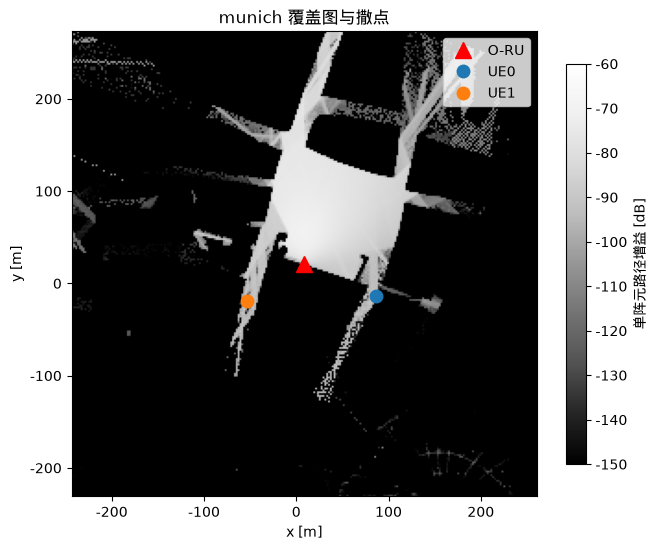

In [3]:
if CHANNEL_MODEL == "rt":
    rt = sim.channel.model                    # oran.rt_channel.RTChannel
    scene = rt.scene                          # oran.rt_channel.RTScene
    positions = scene.drop_ues(NUM_UE, DROP_SEED)
    sim.channel.set_ue_positions(positions)   # 射线追踪 → 频域信道（含链路预算）
    for k in range(NUM_UE):
        print(f"UE{k}：位置 ({positions[k, 0]:6.1f}, {positions[k, 1]:6.1f}) m，路径增益 {rt.path_gain_db()[k]:6.1f} dB，"
              f"宽带 SNR {rt.wideband_snr_db()[k]:5.1f} dB（每接收天线，不含波束赋形增益），{rt.num_paths[k].sum()} 条路径")

    # 覆盖图（单阵元方向图、无折射，撒点用）与 UE 位置
    rm = scene.coverage_map()
    cc = rm.cell_centers.numpy()
    cell = cfg.rt.coverage_cell_size
    pg = db(rm.path_gain.numpy().max(axis=0))
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(pg, origin="lower", cmap="Greys_r", vmin=-150, vmax=-60,
                   extent=[cc[0, 0, 0] - cell / 2, cc[-1, -1, 0] + cell / 2, cc[0, 0, 1] - cell / 2, cc[-1, -1, 1] + cell / 2])
    fig.colorbar(im, ax=ax, label="单阵元路径增益 [dB]", shrink=0.8)
    oru = np.array(cfg.rt.oru_positions[0])
    ax.plot(oru[0], oru[1], "r^", ms=12, label="O-RU")
    for k in range(NUM_UE):
        ax.plot(positions[k, 0], positions[k, 1], "o", ms=9, label=f"UE{k}")
    ax.legend(); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_title("munich 覆盖图与撒点")
    plt.show()
else:
    state0 = sim.channel.sample(1)            # 固定的 CDL 信道实现
    print(f"CDL-{CDL_MODEL}，时延扩展 {DELAY_SPREAD * 1e9:.0f} ns，SNR {SNR_DB} dB")

SNR_RUN = 0.0 if CHANNEL_MODEL == "rt" else SNR_DB   # run_batch / measurement_slot 用的 SNR 参数
NO = 10 ** (-SNR_RUN / 10)                             # 噪声方差（rt 模式为 1）


def make_state(batch_size, sim_=None):
    # 同一信道实现的 batch_size 个连续时隙（UE 静止）
    s = sim_ or sim
    if CHANNEL_MODEL == "rt":
        return s.channel.sample(batch_size)
    h = state0.h_freq
    return ChannelState(h.expand(batch_size, *h.shape[1:]))

三维场景与传播路径（Sionna RT 渲染；红色球为 O-RU，绿色球为 UE，线为传播路径）：

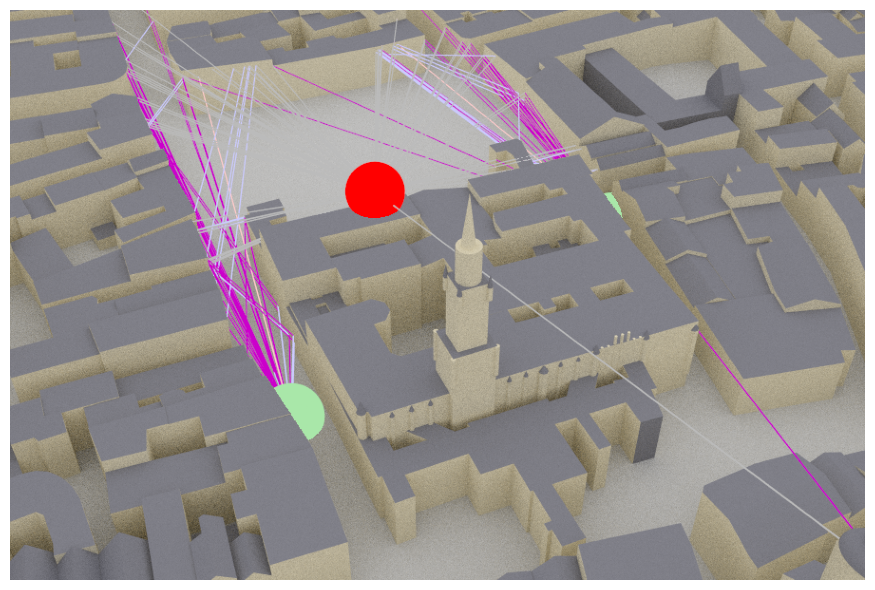

In [4]:
if CHANNEL_MODEL == "rt":
    from sionna.rt import Camera
    paths = scene.solver(scene.scene, max_depth=cfg.rt.max_depth, diffraction=cfg.rt.diffraction,
                         synthetic_array=True)
    center = np.vstack([positions, oru[None]]).mean(axis=0)
    cam = Camera(position=[float(oru[0] - 160), float(oru[1] - 220), 220.0],
                 look_at=[float(center[0]), float(center[1]), 0.0])
    fig = scene.scene.render(camera=cam, paths=paths, resolution=[900, 600], num_samples=64)
    plt.show()

功率时延谱（每条路径的功率，对所有天线平均）与频域响应（一对收发天线）。时延扩展越大，频域起伏越快；
每个 UE 以最早到达的路径为定时零点，首径弱、强径晚到时会出现明显的线性相位（见第 7 节的定时偏差补偿）。

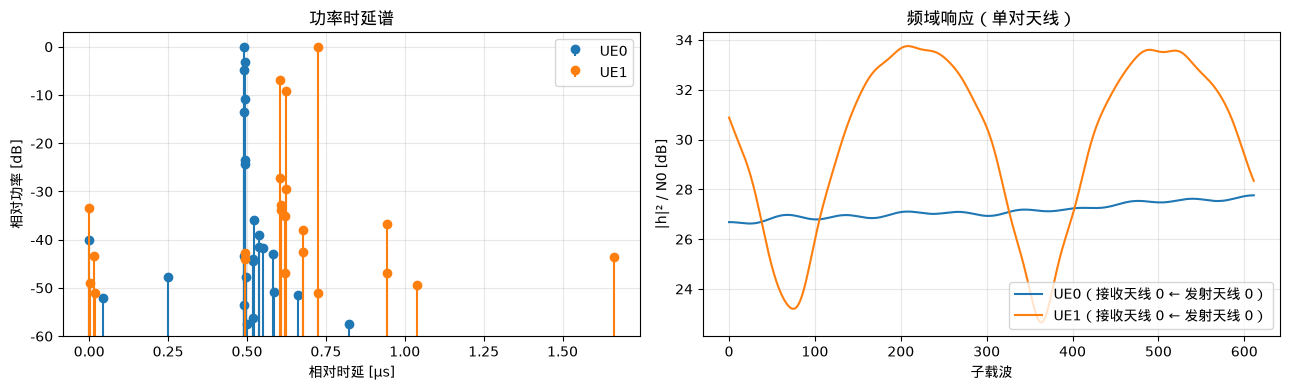

In [5]:
if CHANNEL_MODEL == "rt":
    a, tau = scene.cir()                                  # a: [K, N_r, O-RU, N_TRX, 路径]，tau: [K, O-RU, 路径]
    p = (a.abs() ** 2).mean(dim=(1, 3))                   # [K, O-RU, 路径]
else:
    a, tau = sim.channel.model(1, 1, 1.0)                 # CDL：[1, K, N_r, O-RU, N_TRX, 路径, 1]
    a, tau = a[0, ..., 0], tau[0]
    p = (a.abs() ** 2).mean(dim=(1, 3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k in range(NUM_UE):
    t, pk = tau[k, 0].cpu().numpy(), p[k, 0].cpu().numpy()
    valid = (t >= 0) & (pk > 0)
    t, pk = t[valid] - t[valid].min(), pk[valid]
    rel = db(pk / pk.max())
    keep = rel > -60
    axes[0].stem(t[keep] * 1e6, rel[keep], linefmt=f"C{k}-", markerfmt=f"C{k}o", basefmt=" ", bottom=-60,
                 label=f"UE{k}")
axes[0].set_ylim(-60, 3); axes[0].set_xlabel("相对时延 [µs]"); axes[0].set_ylabel("相对功率 [dB]")
axes[0].set_title("功率时延谱"); axes[0].legend(); axes[0].grid(alpha=0.3)
h = make_state(1).h_freq                                  # [1, K, N_r, O-RU, N_TRX, 符号, 子载波]
for k in range(NUM_UE):
    axes[1].plot(db(h[0, k, 0, 0, 0, 3].abs().cpu().numpy() ** 2 / NO), label=f"UE{k}（接收天线 0 ← 发射天线 0）")
axes[1].set_xlabel("子载波"); axes[1].set_ylabel("|h|² / N0 [dB]"); axes[1].set_title("频域响应（单对天线）")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. 资源网格：PDSCH、DMRS、CSI-RS / CSI-IM

- **数据时隙**：14 个符号都给 PDSCH；DMRS Type 1，符号 2、11。每个 UE 的层占不同 DMRS 端口，MU 时两个 CDM 组都不放数据。
- **测量时隙**（每个 CSI-RS 周期的第 1 个时隙）：符号 12 上放每个 UE 的预编码 NZP CSI-RS（信道测量资源 CMR，
  2 端口时为 TS 38.211 表 7.4.1.5.3-1 第 3 行，fd-CDM2）和 CSI-IM（pattern1，4 个子载波）。PDSCH 在这些 RE 上打孔。
  配对 UE 的 CMR 同时作为本 UE 的干扰测量资源（NZP-IMR）。

UE0：RNTI 100，DMRS 端口 [0, 1]（CDM 组 [0, 0]），DMRS 符号 [2, 11]，不放数据的 CDM 组数 2
UE1：RNTI 101，DMRS 端口 [2, 3]（CDM 组 [1, 1]），DMRS 符号 [2, 11]，不放数据的 CDM 组数 2
每层数据 RE：7344（一个时隙）
CSI-RS：表 7.4.1.5.3-1 第 3 行，CDM 长度 2，符号 12，CSI-IM 起始子载波 4，每 PRB 占 8 个 RE


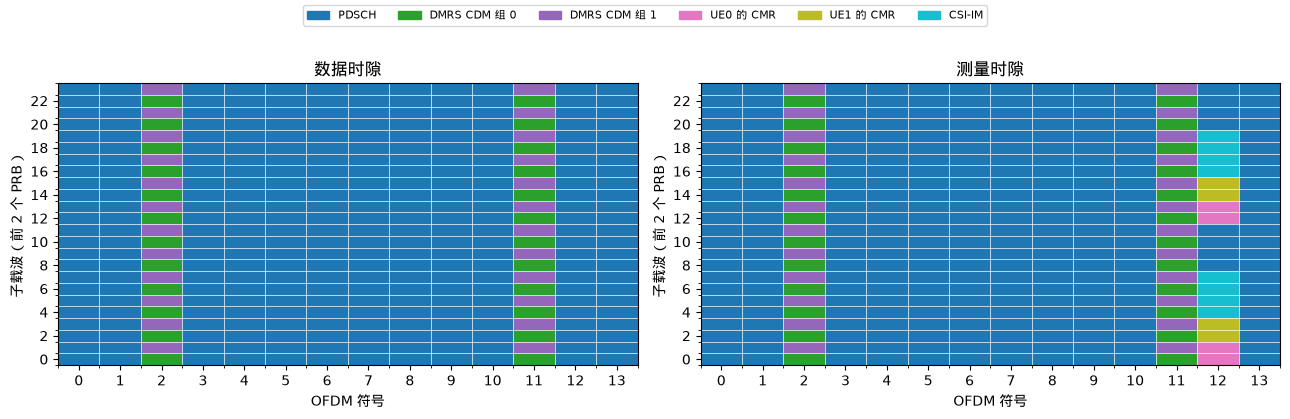

In [6]:
for k, pc in enumerate(sim.pdsch_configs):
    print(f"UE{k}：RNTI {pc.n_rnti}，DMRS 端口 {pc.dmrs.dmrs_port_set}（CDM 组 {list(pc.dmrs.cdm_groups)}），"
          f"DMRS 符号 {list(pc.dmrs_symbol_indices)}，不放数据的 CDM 组数 {pc.dmrs.num_cdm_groups_without_data}")
print(f"每层数据 RE：{sim.rg.num_data_symbols}（一个时隙）")

csirs = CSIRS(cfg, sim.pdsch_configs[0], device=DEVICE)
print(f"CSI-RS：表 7.4.1.5.3-1 第 {csirs.row} 行，CDM 长度 {csirs.cdm}，符号 {csirs.symbol}，"
      f"CSI-IM 起始子载波 {csirs.im_offset}，每 PRB 占 {csirs.overhead_re_per_prb} 个 RE")

# 画前 2 个 PRB：0 PDSCH，1/2 DMRS（CDM 组 0/1），3+k UE k 的 CMR，最后一类为 CSI-IM
F = 24
pp = sim.rg.pilot_pattern
mask = pp.mask.cpu().numpy().astype(bool)                 # [UE, 层, 符号, 子载波]
pil = pp.pilots.cpu().numpy()                             # [UE, 层, 导频]
data_grid = np.zeros((14, F), int)
for t in range(mask.shape[0]):
    for s in range(mask.shape[1]):
        pos = np.argwhere(mask[t, s])
        nz = np.abs(pil[t, s]) > 0
        group = sim.pdsch_configs[t].dmrs.cdm_groups[s]
        for l, kk in pos[nz]:
            if kk < F:
                data_grid[l, kk] = 1 + group
meas_grid = data_grid.copy()
for k in range(NUM_UE):
    sc = csirs.cmr_sc[k].reshape(-1)
    meas_grid[csirs.symbol, sc[sc < F]] = 3 + k
im_cls = 3 + NUM_UE
meas_grid[csirs.symbol, csirs.im_sc.reshape(-1)[csirs.im_sc.reshape(-1) < F]] = im_cls

names = ["PDSCH", "DMRS CDM 组 0", "DMRS CDM 组 1"] + [f"UE{k} 的 CMR" for k in range(NUM_UE)] + ["CSI-IM"]
cmap = plt.get_cmap("tab10", len(names))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, g, title in ((axes[0], data_grid, "数据时隙"), (axes[1], meas_grid, "测量时隙")):
    ax.imshow(g.T, origin="lower", cmap=cmap, vmin=-0.5, vmax=len(names) - 0.5, aspect="auto")
    ax.set_xlabel("OFDM 符号"); ax.set_ylabel("子载波（前 2 个 PRB）"); ax.set_title(title)
    ax.set_xticks(range(14)); ax.set_yticks(range(0, F, 2))
    ax.set_xticks(np.arange(-0.5, 14), minor=True); ax.set_yticks(np.arange(-0.5, F), minor=True)
    ax.grid(which="minor", color="w", lw=0.5)
fig.legend(handles=[Patch(color=cmap(i), label=n) for i, n in enumerate(names)], loc="upper center",
           ncol=len(names), fontsize=8)
plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

## 4. 预编码（O-DU）

TDD 互易：O-DU 由 SRS 得到下行信道（这里假设理想），在每个 PRG（2 PRB）中心子载波处计算块对角化（BD）预编码 $W$，
使 UE k 的层落在其他 UE 信道的零空间内。$\|W\|_F = 1$，每层功率相同。
Cat A 中 O-DU 直接用 $W$ 预编码；Cat B 中 $W$ 经 C-plane（可压缩）下发给 O-RU。

左图：各 UE 收到的各层功率（相对噪声）。对角块是本 UE 的层，非对角块是 BD 零陷后的残余干扰。
右图：UE0 收到的本 UE 层与配对 UE 层的功率随子载波的变化。BD 只在每个 PRG 的中心子载波处精确置零，PRG 内信道变化会留下残余干扰。

CSI (1, 26, 2, 4, 8) → 预编码 W (1, 26, 8, 4)，||W||_F² = 1.000


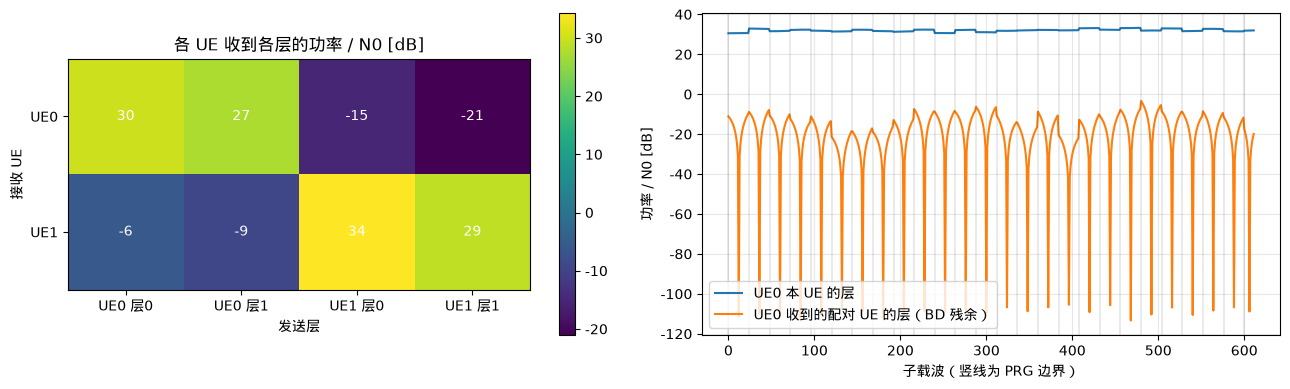

In [7]:
state = make_state(1)
h_csi = sim.channel.csi(state, sim.csi_symbol)             # [1, PRG 数, K, N_r, N_t]
w = sim.odu.precoder(h_csi)                                # [1, PRG 数, N_t, L]
print(f"CSI {tuple(h_csi.shape)} → 预编码 W {tuple(w.shape)}，||W||_F² = {float((w.abs() ** 2).sum((-1, -2)).mean()):.3f}")

g = effective_channel(state.stacked(), w, sim.odu.prg_of_sc)   # 等效信道 H·W：[1, K, N_r, L, 符号, 子载波]
p = (g.abs() ** 2)[0, :, :, :, 3, :].sum(dim=1)                 # 各 UE 收到各层的功率（对接收天线求和）[K, L, F]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pm = db(p.mean(-1).cpu().numpy() / NO)
im = axes[0].imshow(pm, cmap="viridis")
for i in range(pm.shape[0]):
    for j in range(pm.shape[1]):
        axes[0].text(j, i, f"{pm[i, j]:.0f}", ha="center", va="center", color="w")
axes[0].set_xticks(range(pm.shape[1]))
axes[0].set_xticklabels([f"UE{l // LAYERS_PER_UE} 层{l % LAYERS_PER_UE}" for l in range(pm.shape[1])])
axes[0].set_yticks(range(pm.shape[0])); axes[0].set_yticklabels([f"UE{k}" for k in range(pm.shape[0])])
axes[0].set_xlabel("发送层"); axes[0].set_ylabel("接收 UE"); axes[0].set_title("各 UE 收到各层的功率 / N0 [dB]")
fig.colorbar(im, ax=axes[0])
nu = LAYERS_PER_UE
axes[1].plot(db(p[0, :nu].sum(0).cpu().numpy() / NO), label="UE0 本 UE 的层")
if NUM_UE > 1:
    axes[1].plot(db(p[0, nu:].sum(0).cpu().numpy() / NO), label="UE0 收到的配对 UE 的层（BD 残余）")
for b in range(0, cfg.num_subcarriers, 12 * cfg.prg_num_prb):
    axes[1].axvline(b, color="k", lw=0.3, alpha=0.4)
axes[1].set_xlabel("子载波（竖线为 PRG 边界）"); axes[1].set_ylabel("功率 / N0 [dB]"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. 测量时隙与 CQI（UE）

测量时隙中，CSI-RS / CSI-IM 与 PDSCH 一起经前传（Cat A/B、压缩）、O-RU、信道到达 UE（`ORANDownlink.measurement_slot`）。UE 侧（`CSIRSReceiver`）：

1. 用 PDSCH DMRS 估计的相位斜率补偿定时；
2. 每个 PRB 用 CMR 的 2 个 RE 做 LS + CDM2 解扩，得到本 UE 各端口（层）的等效信道；
3. CSI-IM 上的平均功率作为噪声方差（**压缩后值为 0 的 RE 仍为 0，所以这里测不到压缩失真**）；
4. 配对 UE 的 CMR（NZP-IMR）给出多用户干扰协方差（扣除估计噪声）；
5. 每 PRB、每层的 LMMSE SINR → EESM 有效 SINR → 满足 TBLER ≤ 0.1 的最大 CQI（TS 38.214 §5.2.2.1，CSI 参考资源按 §5.2.2.5.1）。

作为对照，"精灵" CQI 直接用真实等效信道计算，不经前传。

UE0：CSI-IM 测得噪声   0.20 dB（真值   0.00 dB），NZP-IMR 测得 INR  -0.2 dB
      CSI-RS：有效 SINR  25.0 dB → CQI 14   ｜   精灵：有效 SINR  27.9 dB → CQI 15
UE1：CSI-IM 测得噪声  -0.00 dB（真值   0.00 dB），NZP-IMR 测得 INR   2.2 dB
      CSI-RS：有效 SINR  23.0 dB → CQI 13   ｜   精灵：有效 SINR  24.8 dB → CQI 14


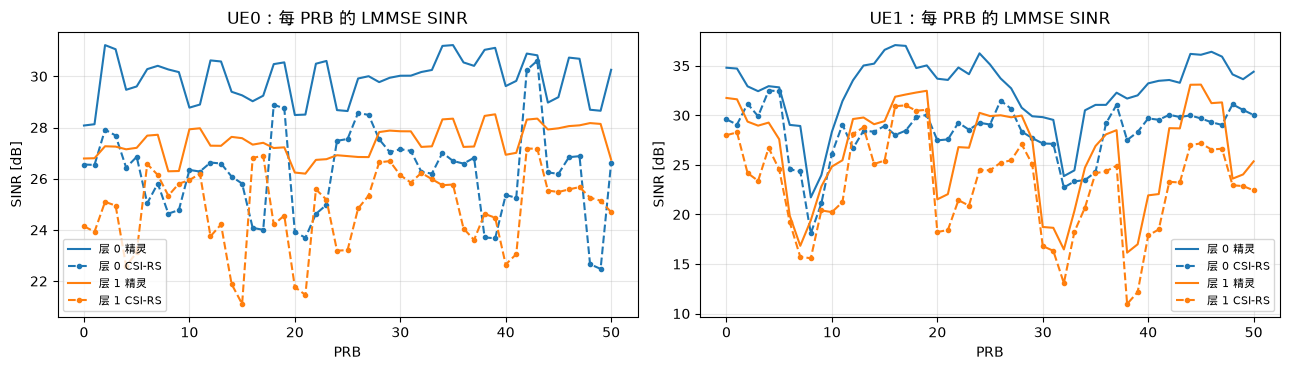

In [8]:
model = AWGNLinkModel(0.1, device=DEVICE)                  # AWGN 链路抽象：各 (Qm, R) 的 TBLER 门限、EESM
pc0 = sim.pdsch_configs[0]
REF_SYMBOLS = reference_data_symbols(pc0)                  # CSI 参考资源中的数据符号
reporter = CQIReporter(MCS_TABLE, reference_num_re(pc0, cfg.num_prb, LAYERS_PER_UE), model)


def genie_cqi(sim_, state_):
    h_ = state_.stacked()[:1][..., REF_SYMBOLS, :]
    w_ = sim_.odu.precoder(sim_.channel.csi(state_, sim_.csi_symbol)[:1])
    sinr = lmmse_sinr(h_, w_, NO, sim_.odu.prg_of_sc, LAYERS_PER_UE)[0]     # [K, ν, 符号, 子载波]
    return reporter(sinr), sinr


def csirs_cqi(sim_, state_, csi_rx_):
    y_ = sim_.measurement_slot(state_, SNR_RUN, csirs)                      # 测量时隙经前传到达 UE
    sinr, diag = csi_rx_.sinr(y_)                                           # [1, K, ν, PRB]
    return reporter(sinr[0]), sinr[0], diag


csi_rx = CSIRSReceiver(csirs, cfg.prg_num_prb, sim.ue.estimator)
state = make_state(1)
(cqi_g, eff_g), sinr_g = genie_cqi(sim, state)
(cqi_r, eff_r), sinr_r, diag = csirs_cqi(sim, state, csi_rx)
for k in range(NUM_UE):
    inr = f"，NZP-IMR 测得 INR {db(diag['inr'][0, k].item()):5.1f} dB" if NUM_UE > 1 else ""
    print(f"UE{k}：CSI-IM 测得噪声 {db(diag['noise'][0, k].item()):6.2f} dB（真值 {db(NO):6.2f} dB）{inr}")
    print(f"      CSI-RS：有效 SINR {eff_r[k]:5.1f} dB → CQI {cqi_r[k]:2d}   ｜   精灵：有效 SINR {eff_g[k]:5.1f} dB → CQI {cqi_g[k]:2d}")

fig, axes = plt.subplots(1, NUM_UE, figsize=(6.5 * NUM_UE, 3.8), squeeze=False)
for k in range(NUM_UE):
    ax = axes[0, k]
    for l in range(LAYERS_PER_UE):
        gl = sinr_g[k, l].mean(0).reshape(cfg.num_prb, 12).mean(-1).cpu().numpy()   # 精灵：每 PRB 平均
        ax.plot(db(gl), f"C{l}-", label=f"层 {l} 精灵")
        ax.plot(db(sinr_r[k, l].cpu().numpy()), f"C{l}--", marker=".", label=f"层 {l} CSI-RS")
    ax.set_xlabel("PRB"); ax.set_ylabel("SINR [dB]"); ax.set_title(f"UE{k}：每 PRB 的 LMMSE SINR")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. 链路自适应（MAC）

3GPP 不规定 gNB 如何用 CQI。这里的做法（`LinkAdaptation`）：CQI → 该 CQI 的门限 SINR（保守下界）→ 加 OLLA 偏移 →
取门限不超过它的最大 MCS（门限按实际 PDSCH 分配计算）。OLLA：每个 ACK 偏移 +δ·p/(1−p)，每个 NACK 偏移 −δ，
使首传 BLER 收敛到 p = 0.1。

Sionna 的 LDPC 编码器不支持重复编码，码率过低的 MCS 无法实现，`supported_mcs()` 逐个尝试建立编码链来确定可用 MCS（约 10 秒）。

可用 MCS：[3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27]（5.4 s）


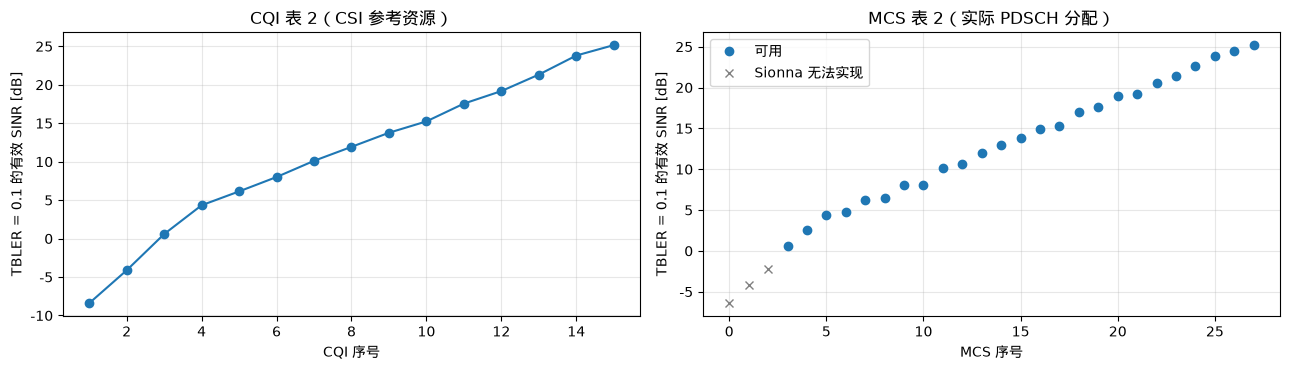

UE0：CQI 14 → SINR 估计  23.8 dB（含 OLLA 偏移 +0.0 dB） → MCS 25（256QAM，R = 885/1024）→ TBS 102416 bit
UE1：CQI 13 → SINR 估计  21.3 dB（含 OLLA 偏移 +0.0 dB） → MCS 22（256QAM，R = 754/1024）→ TBS 86040 bit


In [9]:
t0 = time.time()
allowed = sim.supported_mcs()
la = LinkAdaptation(LinkAdaptationConfig(olla=OLLA), MCS_TABLE, NUM_UE,
                    sim.rg.num_data_symbols * LAYERS_PER_UE, reporter, model, allowed)
print(f"可用 MCS：{allowed}（{time.time() - t0:.1f} s）")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(range(1, 16), reporter.threshold_db, "o-")
axes[0].set_xlabel("CQI 序号"); axes[0].set_ylabel("TBLER = 0.1 的有效 SINR [dB]")
axes[0].set_title(f"CQI 表 {MCS_TABLE}（CSI 参考资源）"); axes[0].grid(alpha=0.3)
ok = np.isin(np.arange(len(la.mcs_threshold_db)), allowed)
axes[1].plot(np.flatnonzero(ok), la.mcs_threshold_db[ok], "o", label="可用")
axes[1].plot(np.flatnonzero(~ok), la.mcs_threshold_db[~ok], "x", color="gray", label="Sionna 无法实现")
axes[1].set_xlabel("MCS 序号"); axes[1].set_ylabel("TBLER = 0.1 的有效 SINR [dB]")
axes[1].set_title(f"MCS 表 {MCS_TABLE}（实际 PDSCH 分配）"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

cqi = cqi_r if CQI_SOURCE == "csi-rs" else cqi_g
mcs = la.select_mcs(cqi)
sim.set_mcs(mcs)                                           # O-DU 编码链与 UE 译码链切换到新的 MCS（按 MCS 缓存）
for k in range(NUM_UE):
    qm, r = mcs_entry(MCS_TABLE, int(mcs[k]))
    print(f"UE{k}：CQI {cqi[k]} → SINR 估计 {la.sinr_estimate_db(cqi)[k]:5.1f} dB（含 OLLA 偏移 {la.offset_db[k]:+.1f} dB）"
          f" → MCS {mcs[k]}（{2 ** qm}QAM，R = {r:.0f}/1024）→ TBS {sim.tb_sizes[k]} bit")

## 7. 数据时隙：逐模块走一遍 PDSCH

一个批次 = 同一信道上 `SLOTS_PER_PERIOD` 个连续时隙（同一 MCS）。下面把 `ORANDownlink.run_batch` 拆开逐步执行。

### 7.1 O-DU High-PHY

TB CRC → 码块分割 + CB CRC → LDPC → 速率匹配 → 加扰（`TBEncoder`，TS 38.212 §7.2）→ QAM 调制 → 层映射 → RE 映射（数据 + DMRS），
Cat A 再按 PRG 预编码。

UE0 编码链：信息比特 102416 → 13 个码块（每块 7904 bit，含 CB CRC）→ LDPC + 速率匹配 → 编码比特 117504（码率 0.872）→ 8 bit/符号 → QAM 符号 14688 → 层映射 (2, 7344)
层资源网格 x_layers (7, 4, 14, 612)（批次, 层, 符号, 子载波）
送往 O-RU 的 U-plane (7, 8, 14, 612)：Cat A，已预编码的天线端口流


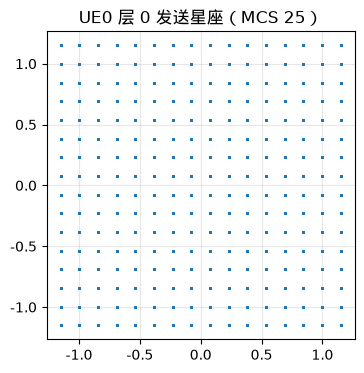

In [10]:
B = SLOTS_PER_PERIOD
state = make_state(B)
h_csi = sim.channel.csi(state, sim.csi_symbol)

enc, mapper, lmap = sim.odu.tb_encoders[0], sim.odu.mappers[0], sim.odu.layer_mappers[0]
b = sim.odu.binary_source([1, 1, enc.tb_size])
c = enc(b)
s = mapper(c)
xl = lmap(s)
print(f"UE0 编码链：信息比特 {enc.tb_size} → {enc.num_cbs} 个码块（每块 {enc.ldpc_encoder.k} bit，含 CB CRC）→ LDPC + 速率匹配 → "
      f"编码比特 {c.shape[-1]}（码率 {enc.coderate:.3f}）→ {mapper.constellation.num_bits_per_symbol} bit/符号 → "
      f"QAM 符号 {s.shape[-1]} → 层映射 {tuple(xl.shape[-2:])}")

tx = sim.odu(B, h_csi)                                     # 整个 O-DU（所有 UE、B 个时隙）
print(f"层资源网格 x_layers {tuple(tx.x_layers.shape)}（批次, 层, 符号, 子载波）")
print(f"送往 O-RU 的 U-plane {tuple(tx.uplane[0].shape)}："
      + ("Cat A，已预编码的天线端口流" if CATEGORY == "A" else f"Cat B，层流；C-plane 权值 {tuple(tx.weights[0].shape)}"))

fig, ax = plt.subplots(figsize=(4, 4))
x0 = tx.x_data[0, 0, 0].cpu().numpy()
ax.plot(x0.real, x0.imag, ".", ms=2); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_title(f"UE0 层 0 发送星座（MCS {mcs[0]}）"); plt.show()

### 7.2 前传（O-RAN 7.2x U-plane / C-plane）

U-plane：16 bit 定点 → 按 PRB（12 个 RE）分块压缩（O-RAN WG4 CUS 附录 A）→ 传输 → 解压。
Cat B 的 C-plane 波束赋形权值按 PRB bundle 压缩（Section Extension 11）。
下表为 100 MHz（273 PRB）时单个 O-RU 链路的前传比特率（含 eCPRI 与以太网开销）。

U-plane：mu_law 5 bit，SQNR 25.0 dB，削顶 0 个

前传比特率（100 MHz，单个 O-RU）：
          ideal 16 bit：Cat A  24.57 Gbps，Cat B  12.59 Gbps
            bfp  9 bit：Cat A  14.35 Gbps，Cat B   7.36 Gbps
            bfp  7 bit：Cat A  11.31 Gbps，Cat B   5.81 Gbps
            bfp  5 bit：Cat A   8.16 Gbps，Cat B   4.20 Gbps
  block_scaling  7 bit：Cat A  11.31 Gbps，Cat B   5.81 Gbps
         mu_law  7 bit：Cat A  11.31 Gbps，Cat B   5.81 Gbps


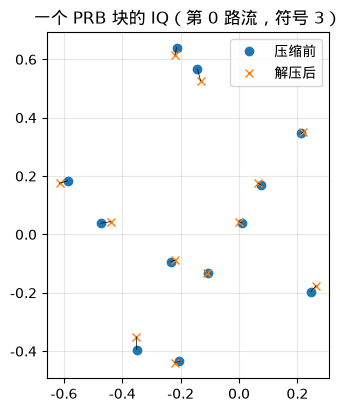

In [11]:
fh = sim.fronthaul[0]
fh.reset_stats()
uplane_hat, w_hat = fh.transmit(tx.uplane[0], tx.weights[0])
print(f"U-plane：{cfg.uplane.method} {cfg.uplane.iq_width} bit，SQNR {fh.uplane.stats.sqnr_db:.1f} dB，"
      f"削顶 {fh.uplane.stats.num_clipped} 个")
if w_hat is not None:
    print(f"C-plane 权值：{cfg.bfw.method} {cfg.bfw.iq_width} bit，SQNR {fh.bfw.stats.sqnr_db:.1f} dB")

print("\n前传比特率（100 MHz，单个 O-RU）：")
for comp in [("ideal", 16), ("bfp", 9), ("bfp", 7), ("bfp", 5), ("block_scaling", 7), ("mu_law", 7)]:
    rates = [fronthaul_rate(replace(cfg, category=cat, uplane=CompressionConfig(*comp), bfw=CompressionConfig(*comp)),
                            num_prb=273).total / 1e9 for cat in ("A", "B")]
    print(f"  {comp[0]:>13} {comp[1]:2d} bit：Cat A {rates[0]:6.2f} Gbps，Cat B {rates[1]:6.2f} Gbps")

# 一个压缩块（第 0 路流、符号 3、PRB 0）的 IQ：压缩前后
blk, blk_hat = tx.uplane[0][0, 0, 3, :12].cpu().numpy(), uplane_hat[0, 0, 3, :12].cpu().numpy()
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(blk.real, blk.imag, "o", label="压缩前")
ax.plot(blk_hat.real, blk_hat.imag, "x", label="解压后")
for u, v in zip(blk, blk_hat):
    ax.plot([u.real, v.real], [u.imag, v.imag], "k-", lw=0.5)
ax.set_aspect("equal"); ax.legend(); ax.grid(alpha=0.3); ax.set_title("一个 PRB 块的 IQ（第 0 路流，符号 3）")
plt.show()

### 7.3 O-RU

Cat B：按 C-plane 下发的（解压后的）权值逐 RE 预编码；Cat A：直通。之后（时域仿真时）IFFT + CP。
发射 EVM 只反映前传失真：O-RU 天线口信号相对"理想前传"（不压缩、权值不量化）的误差。

In [12]:
oru = sim.orus[0]
grid = oru.frequency_domain(uplane_hat, w_hat)             # 各天线频域网格 [B, N_TRX, 符号, 子载波]
ideal = apply_precoder(tx.x_layers, tx.w, sim.odu.prg_of_sc)
tx_evm = float(((grid - ideal).abs() ** 2).sum() / (ideal.abs() ** 2).sum()) ** 0.5
print(f"O-RU 天线口 {tuple(grid.shape)}，发射 EVM {100 * tx_evm:.2f} %（{db(tx_evm ** 2):.1f} dB）")
x_air = oru.to_air(grid)

O-RU 天线口 (7, 8, 14, 612)，发射 EVM 5.61 %（-25.0 dB）


### 7.4 信道与 UE 接收机

$y = H x + n$，之后 UE：DMRS 信道估计（定时偏差补偿 + LS + PRG 内 CDM 分离与插值）→ LMMSE 均衡（配对 UE 的层作为干扰白化）
→ 软解调 → 解层映射 → 解扰 / 速率解匹配 / LDPC 译码 → CRC。

UE0：DMRS 信道估计 NMSE  -27.0 dB
UE1：DMRS 信道估计 NMSE  -28.5 dB


UE0：MCS 25，7 个时隙 CRC [0, 0, 0, 0, 0, 0, 0]，BLER 1.00，均衡后 SINR  21.7 dB（EVM 8.25 %）
UE1：MCS 22，7 个时隙 CRC [1, 1, 1, 1, 1, 1, 1]，BLER 0.00，均衡后 SINR  18.9 dB（EVM 11.39 %）


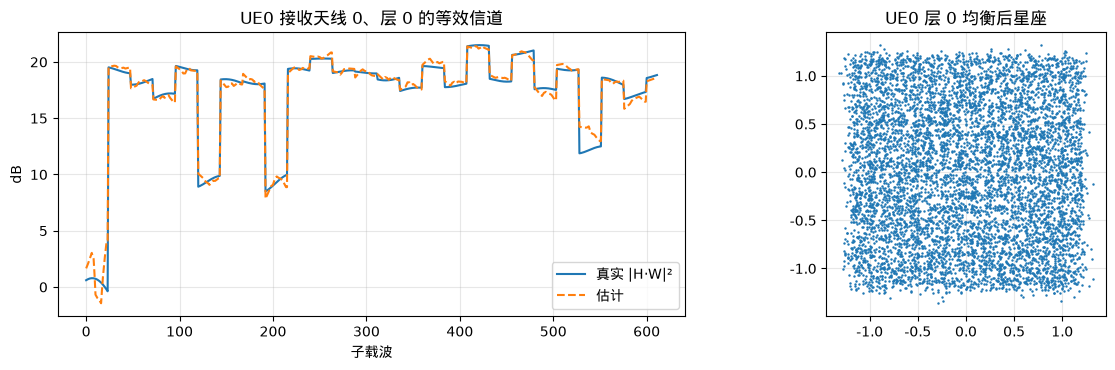

In [13]:
y = sim.channel(x_air[:, None], state, NO)                 # [B, K, N_r, 符号, 子载波]
y_grid = sim.ue.frequency_grid(y)
w_applied = w_hat if w_hat is not None else tx.w           # O-RU 实际使用的权值
h_true = effective_channel(state.stacked(), w_applied, sim.odu.prg_of_sc).unflatten(3, (NUM_UE, LAYERS_PER_UE))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
if sim.ue.estimator is not None:
    h_hat, err_var = sim.ue.estimator(y_grid, torch.tensor(NO, device=y.device))   # [B, K, N_r, K, ν, 符号, 子载波]
    for k in range(NUM_UE):
        e = (h_hat[:, k, :, k] - h_true[:, k, :, k]).abs() ** 2
        print(f"UE{k}：DMRS 信道估计 NMSE {db(float(e.mean() / (h_true[:, k, :, k].abs() ** 2).mean())):6.1f} dB")
    hh, ht = h_hat[0, 0, 0, 0, 0, 3].cpu().numpy(), h_true[0, 0, 0, 0, 0, 3].cpu().numpy()
    axes[0].plot(db(np.abs(ht) ** 2), label="真实 |H·W|²"); axes[0].plot(db(np.abs(hh) ** 2), "--", label="估计")
    axes[0].set_xlabel("子载波"); axes[0].set_ylabel("dB"); axes[0].set_title("UE0 接收天线 0、层 0 的等效信道")
    axes[0].legend(); axes[0].grid(alpha=0.3)
rx = sim.ue(y, NO, h_true if CHANNEL_ESTIMATION == "perfect" else None)
crc = rx.crc_ok.cpu().numpy()                              # [B, K]
for k in range(NUM_UE):
    err = (rx.x_hat[:, k] - tx.x_data[:, k]).abs() ** 2
    sinr_data = float((tx.x_data[:, k].abs() ** 2).sum() / err.sum())
    print(f"UE{k}：MCS {mcs[k]}，{B} 个时隙 CRC {crc[:, k].astype(int).tolist()}，BLER {1 - crc[:, k].mean():.2f}，"
          f"均衡后 SINR {db(sinr_data):5.1f} dB（EVM {100 / sinr_data ** 0.5:.2f} %）")
xh = rx.x_hat[0, 0, 0].cpu().numpy()
axes[1].plot(xh.real, xh.imag, ".", ms=1.5); axes[1].set_aspect("equal"); axes[1].grid(alpha=0.3)
axes[1].set_title("UE0 层 0 均衡后星座")
plt.tight_layout(); plt.show()

## 8. 闭环：多个 CSI-RS 周期

每个周期：测量时隙 → CQI（CSI-RS 或精灵）→ MCS（+ OLLA）→ `SLOTS_PER_PERIOD` 个数据时隙（`run_batch`）→ ACK/NACK 更新 OLLA。
UE 静止时信道不变，MCS 主要随 OLLA 变化。BLER 随 MCS 近似阶跃变化，所以 OLLA 会在临界 MCS 附近来回调整。

12 个周期（96 个时隙）用时 6.7 s；统计跳过前 3 个周期
UE0：吞吐  137.8 Mbps，首传 BLER 0.159，最终 OLLA 偏移 -4.06 dB
UE1：吞吐  153.4 Mbps，首传 BLER 0.048，最终 OLLA 偏移 -0.72 dB


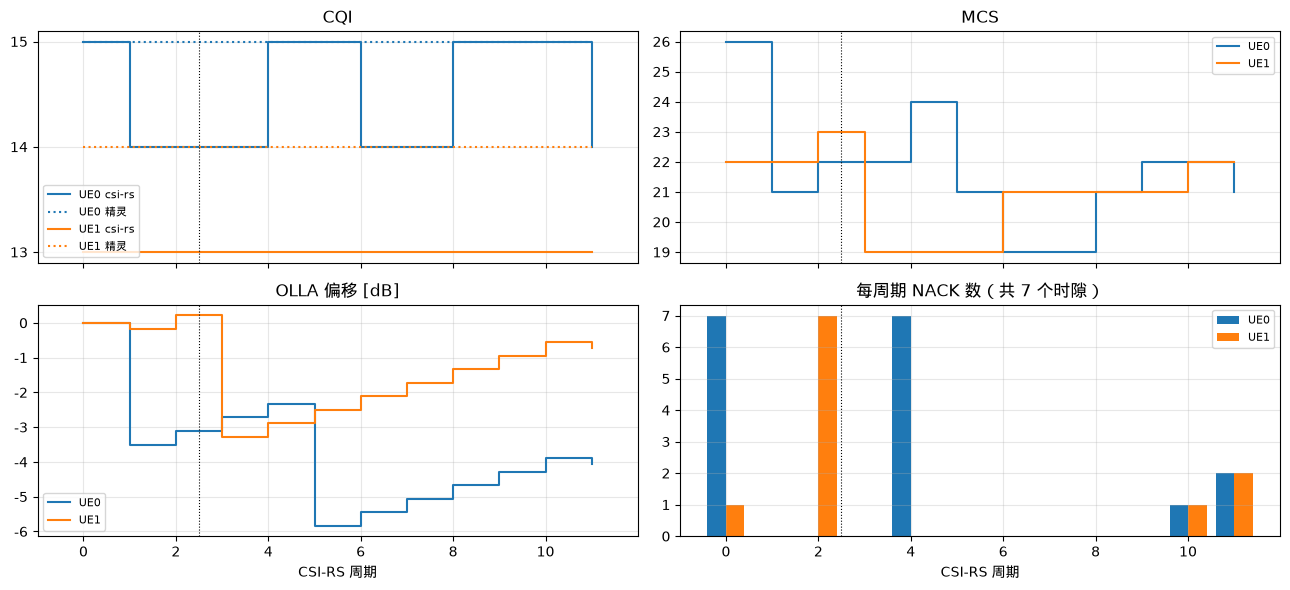

In [14]:
def run_closed_loop(sim_, csi_rx_, num_periods=NUM_PERIODS, slots=SLOTS_PER_PERIOD, seed=SEED):
    sionna_config.seed = seed
    la.reset()
    sim_.reset_stats()
    hist = {k: [] for k in ("cqi", "cqi_genie", "mcs", "offset", "nack", "tbs", "inr")}
    for _ in range(num_periods):
        state_ = make_state(slots, sim_)
        (cqi_g_, _), _ = genie_cqi(sim_, state_)
        if CQI_SOURCE == "csi-rs":
            (cqi_, _), _, diag_ = csirs_cqi(sim_, state_, csi_rx_)
            hist["inr"].append(db(diag_["inr"][0].cpu().numpy()))
        else:
            cqi_ = cqi_g_
        hist["offset"].append(la.offset_db.copy())
        mcs_ = la.select_mcs(cqi_)
        sim_.set_mcs(mcs_)
        st = sim_.run_batch(slots, SNR_RUN, state=state_)
        nack = st.block_errors.astype(int)
        la.update(slots - nack, nack, mcs_)
        for key, v in (("cqi", cqi_), ("cqi_genie", cqi_g_), ("mcs", mcs_), ("nack", nack),
                       ("tbs", np.array(sim_.tb_sizes))):
            hist[key].append(v)
    hist = {k: np.array(v) for k, v in hist.items()}
    m = slice(WARMUP_PERIODS, None)
    n_slots = len(hist["nack"][m]) * slots
    hist["bler"] = hist["nack"][m].sum(0) / n_slots
    hist["tput_mbps"] = ((slots - hist["nack"][m]) * hist["tbs"][m]).sum(0) / n_slots * cfg.slots_per_second / 1e6
    return hist


t0 = time.time()
hist = run_closed_loop(sim, csi_rx)
print(f"{NUM_PERIODS} 个周期（{NUM_PERIODS * (SLOTS_PER_PERIOD + 1)} 个时隙）用时 {time.time() - t0:.1f} s；"
      f"统计跳过前 {WARMUP_PERIODS} 个周期")
for k in range(NUM_UE):
    print(f"UE{k}：吞吐 {hist['tput_mbps'][k]:6.1f} Mbps，首传 BLER {hist['bler'][k]:.3f}，"
          f"最终 OLLA 偏移 {hist['offset'][-1, k]:+.2f} dB")

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True)
x = np.arange(NUM_PERIODS)
for k in range(NUM_UE):
    axes[0, 0].step(x, hist["cqi"][:, k], where="post", color=f"C{k}", label=f"UE{k} {CQI_SOURCE}")
    axes[0, 0].step(x, hist["cqi_genie"][:, k], where="post", color=f"C{k}", ls=":", label=f"UE{k} 精灵")
    axes[0, 1].step(x, hist["mcs"][:, k], where="post", color=f"C{k}", label=f"UE{k}")
    axes[1, 0].step(x, hist["offset"][:, k], where="post", color=f"C{k}", label=f"UE{k}")
    axes[1, 1].bar(x + 0.4 * k - 0.2, hist["nack"][:, k], width=0.4, color=f"C{k}", label=f"UE{k}")
for ax, t in zip(axes.flat, ["CQI", "MCS", "OLLA 偏移 [dB]", f"每周期 NACK 数（共 {SLOTS_PER_PERIOD} 个时隙）"]):
    ax.set_title(t); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    ax.axvline(WARMUP_PERIODS - 0.5, color="k", ls=":", lw=0.8)
for ax in axes[1]:
    ax.set_xlabel("CSI-RS 周期")
for ax in (axes[0, 0], axes[0, 1]):
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

## 9. （可选）同一撒点上比较 Cat A/B × 压缩

同一个信道、同一组比特和噪声（相同种子），依次运行 Cat A / Cat B 与 `COMPARE_WIDTHS` 中的各压缩配置（Cat B 的权值与 U-plane 同位宽）。
关注三个量：

- **吞吐量**；
- **OLLA 偏移**：MAC 为满足目标 BLER 把 CQI 下调了多少，即 CSI 没有看到的那部分失真；
- **ΔCQI = CQI − 精灵 CQI**：CSI-RS 测量看到了多少失真。

单个撒点的结果随机性较大，统计结论请用 `scripts/rt_compare_compression.py` 跑多个撒点。

Cat A ideal 16 bit：平均吞吐  188.3 Mbps，BLER 0.079，OLLA 偏移 -0.20 dB，ΔCQI +0.00
Cat A block_scaling  5 bit：平均吞吐  143.1 Mbps，BLER 0.183，OLLA 偏移 -3.20 dB，ΔCQI -0.11
Cat A mu_law  5 bit：平均吞吐  131.3 Mbps，BLER 0.167，OLLA 偏移 -3.70 dB，ΔCQI -0.67
Cat B ideal 16 bit：平均吞吐  183.8 Mbps，BLER 0.095，OLLA 偏移 -0.33 dB，ΔCQI +0.00
Cat B block_scaling  5 bit：平均吞吐  153.0 Mbps，BLER 0.095，OLLA 偏移 -3.51 dB，ΔCQI -0.22
Cat B mu_law  5 bit：平均吞吐  134.9 Mbps，BLER 0.143，OLLA 偏移 -4.16 dB，ΔCQI -0.39
用时 41.4 s


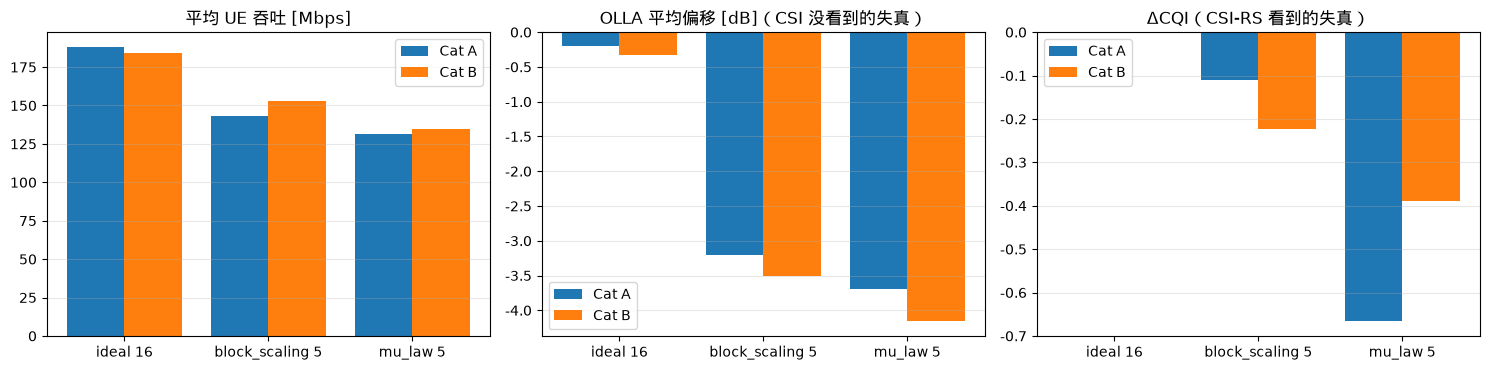

In [15]:
if RUN_COMPARISON:
    results = {}
    t0 = time.time()
    for cat in ("A", "B"):
        cfg_c = replace(cfg, category=cat)
        sim_c = ORANDownlink(cfg_c)
        if CHANNEL_MODEL == "rt":
            sim_c.channel.set_ue_positions(positions)
        csi_rx_c = CSIRSReceiver(csirs, cfg_c.prg_num_prb, sim_c.ue.estimator)
        for comp in COMPARE_WIDTHS:
            sim_c.set_compression(CompressionConfig(*comp), CompressionConfig(*comp))
            h_ = run_closed_loop(sim_c, csi_rx_c)
            results[(cat, comp)] = h_
            m = slice(WARMUP_PERIODS, None)
            dcqi = (h_["cqi"][m] - h_["cqi_genie"][m]).mean()
            print(f"Cat {cat} {comp[0]:>5} {comp[1]:2d} bit：平均吞吐 {h_['tput_mbps'].mean():6.1f} Mbps，"
                  f"BLER {h_['bler'].mean():.3f}，OLLA 偏移 {h_['offset'][m].mean():+5.2f} dB，ΔCQI {dcqi:+.2f}")
    print(f"用时 {time.time() - t0:.1f} s")

    labels = [f"{c[0]} {c[1]}" for c in COMPARE_WIDTHS]
    xs = np.arange(len(COMPARE_WIDTHS))
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    m = slice(WARMUP_PERIODS, None)
    for i, cat in enumerate(("A", "B")):
        hs = [results[(cat, c)] for c in COMPARE_WIDTHS]
        axes[0].bar(xs + 0.4 * i - 0.2, [h_["tput_mbps"].mean() for h_ in hs], 0.4, label=f"Cat {cat}")
        axes[1].bar(xs + 0.4 * i - 0.2, [h_["offset"][m].mean() for h_ in hs], 0.4, label=f"Cat {cat}")
        axes[2].bar(xs + 0.4 * i - 0.2, [(h_["cqi"][m] - h_["cqi_genie"][m]).mean() for h_ in hs], 0.4, label=f"Cat {cat}")
    for ax, t in zip(axes, ["平均 UE 吞吐 [Mbps]", "OLLA 平均偏移 [dB]（CSI 没看到的失真）", "ΔCQI（CSI-RS 看到的失真）"]):
        ax.set_xticks(xs); ax.set_xticklabels(labels); ax.set_title(t); ax.grid(alpha=0.3, axis="y"); ax.legend()
    plt.tight_layout(); plt.show()

## 10. 小结与延伸

- **CSI 能看到什么**：零值 RE 压缩后仍为 0，所以 CSI-IM 测不到压缩失真。MU 时 Cat A 中配对 UE 的 CSI-RS 失真会泄漏到本 UE，
  Cat B 的权值压缩会破坏 BD 零陷，这两项都能被 NZP-IMR 测到。层域自失真（Cat B U-plane）只能由 OLLA 吸收。
- **SU 与 MU 的差别**：SU 时 Cat B 的层域噪声随信号一起被波束赋形，更怕压缩；MU 时 Cat A 的天线域噪声无法被 BD 置零、会泄漏给配对 UE，更怕压缩。
- **批量统计**：`scripts/rt_closed_loop.py`（单一配置、多撒点）、`scripts/rt_compare_compression.py`（Cat A/B × 压缩、配对撒点、两块 GPU 并行）。
- **设计说明与简化**：见 `oran/README.md`。